# RoboGuide AI · Reproducible Final Project
### ITAI 2377 | Domain-Specific AI Assistant | Tung Tung Tung Sahar

**Team roster from the original plan:** José Tuozzo, Kim Nguyen, Huu Huynh.

**This notebook is runnable on a CPU and does not connect to or control an actual PiDog.** It demonstrates evidence-grounded retrieval, version filtering, safe abstention, quality checks, feature engineering, baseline comparisons and evaluation.

> Research integrity: the offline corpus consists of **24 curated summaries** of official manufacturer sources, not 24 downloaded full pages. The source manifest in the rows provides links, and the optional online importer collects fresh pages separately. The manual 43-question benchmark is a small illustrative assessment, not an external study.


In [1]:
# Colab bootstrap: first open this notebook from the repository's GitHub path.
from pathlib import Path
import os,subprocess,sys
if not Path('roboguide').exists():
    if Path('/content').exists():
        repo=Path('/content/Jose-Tuozzo-AI-Portfolio')
        if not repo.exists():
            subprocess.run(['git','clone','--depth','1','https://github.com/jtuozzo1616/Jose-Tuozzo-AI-Portfolio.git',str(repo)],check=True)
        project=repo/'ITAI2377-RoboGuide'
        if not project.exists():
            raise FileNotFoundError('Project folder is not published yet. Upload RoboGuide-AI.zip to Colab and extract it.')
        os.chdir(project)
    else:
        raise RuntimeError('Open the notebook from the RoboGuide-AI root directory.')
# Uncomment next command when new Colab environment lacks dependencies:
# %pip install -q -e '.[test,ui,online]'
print('Working directory:',Path.cwd())


Working directory: /mnt/data/RoboGuide-AI


## 1 · Architectural contract

The original proposal requested a retrieval-augmented assistant with semantic retrieval, engineered metadata (version, entity, API, error fingerprint, authority), a confidence gate, citations and a CPU-only fallback. This implementation prioritizes a **reproducible, validated lexical/character hybrid retriever** on limited CPU resources; neural embeddings/FAISS remain planned work rather than falsely claiming their evaluation. It deliberately produces **extractive answers** so a generator cannot add undocumented commands.

Architecture: source-cited summaries → canonical schema → word/character TF-IDF index → 8 explicit features → version-aware hybrid ranker → evidence gate → cited extractive answer → benchmark + failure review.


In [2]:
from roboguide import RoboGuide,error_fingerprint
from roboguide.evaluation import load_benchmark,quality,run
from roboguide.preprocessing import encode_features
import json,pandas as pd,numpy as np
from pathlib import Path
from IPython.display import display,Image
assistant=RoboGuide()
print('Canonical records:',len(assistant.docs),'| Evaluation questions:',len(load_benchmark()))
print('Official-domain sources:',sorted({x['source_url'].split('/')[2] for x in assistant.docs}))


Canonical records: 24 | Evaluation questions: 43
Official-domain sources: ['docs.sunfounder.com', 'github.com']


## 2 · Source acquisition and preprocessing

The curated pilot is derived from the official PiDog FAQ, calibration guide, preset-actions API, PiDog repository and Robot HAT docs. Every row records an ID, title, version, subsystem, source URL, provenance label and content. `roboguide/ingest.py` can fetch **fresh official HTML** using an allowlist, SHA-256 source manifests, structural HTML cleaning, deduplication and chunking; it marks those chunks **unreviewed** until verified for hardware version and code fidelity. This notebook never quietly mixes the unreviewed corpus into evaluation.

Below, a deliberately corrupted *staging fixture* demonstrates duplicate removal, missing-value restoration from authoritative canonical records, boilerplate elimination and invalid metadata correction. Results measure our cleaning code, not errors in SunFounder's website.


In [3]:
q,raw,processed=quality()
display(pd.DataFrame([{'Stage':k,**q[k]} for k in ('raw','processed')]))
display(pd.DataFrame(processed)[['id','title','subsystem','version','source_url','content']].head(6))


,Stage,rows,missing_required_cells,duplicate_id_rows,boilerplate_rows,noncanonical_version_rows
0,raw,26,2,2,1,1
1,processed,24,0,0,0,0


,id,title,subsystem,version,source_url,content
0,versions,Hardware compatibility: Standard vs V2,hardware,shared,https://docs.sunfounder.com/projects/pidog/en/...,"PiDog Standard/V1 supports Raspberry Pi 3B+, R..."
1,zero_v1,V1 or Standard servo zeroing,calibration,standard,https://docs.sunfounder.com/projects/pidog/en/...,"For Standard/V1 PiDog, use the manufacturer-pr..."
2,zero_v2,V2 servo zero button,calibration,v2,https://docs.sunfounder.com/projects/pidog/en/...,PiDog V2 with Robot HAT V5 has an onboard zero...
3,calibration,Step-by-step calibration with ruler,calibration,shared,https://docs.sunfounder.com/projects/pidog/en/...,Place PiDog on a flat platform. Go to ~/pidog/...
4,unstable,Walking instability and wobbling,motion,shared,https://docs.sunfounder.com/projects/pidog/en/...,If PiDog walks or stands unstably: verify all ...
5,gpio_hat,V2 zero button works but control script fails,hardware,v2,https://docs.sunfounder.com/projects/pidog/en/...,If V2 Robot HAT zero button moves servos but P...


## 3 · Mixed-data encoding and engineered features

Retrieval pairs have **eight engineered numerical candidate features**: word similarity, character similarity, entity overlap, title-token overlap, API match, error-fingerprint match, hardware version compatibility and source authority. The categoricals (subsystem and hardware version) are one-hot encoded. Numerical scalers and category encoders fit **only on development candidates**, then transform the fixed test slice to prevent preprocessor leakage.


In [4]:
table,transform,Xdev,Xtest=encode_features(assistant)
print('Development feature matrix:',Xdev.shape,'| test:',Xtest.shape)
print('Non-finite values:',np.count_nonzero(~np.isfinite(Xdev))+np.count_nonzero(~np.isfinite(Xtest)))
display(table[['subsystem','version','word_similarity','char_similarity','entity_overlap','title_overlap','version_compatibility','source_authority','relevant']].head(8))


Development feature matrix: (835, 26) | test: (190, 26)
Non-finite values: 0


,subsystem,version,word_similarity,char_similarity,entity_overlap,title_overlap,version_compatibility,source_authority,relevant
0,motion,shared,0.074301,0.122648,1.0,0.0,1.0,1.0,1
1,hardware,shared,0.063638,0.052871,1.0,0.0,1.0,1.0,0
2,hardware,v2,0.048602,0.090234,1.0,0.0,0.8,1.0,0
3,calibration,v2,0.045659,0.072182,1.0,0.0,0.8,1.0,0
4,software,shared,0.028832,0.054276,1.0,0.0,1.0,1.0,0
5,calibration,shared,0.000000,0.036780,1.0,0.0,1.0,1.0,1
6,safety,shared,0.000000,0.020179,1.0,0.0,1.0,1.0,0
7,calibration,standard,0.000000,0.001513,1.0,0.0,0.8,1.0,0


In [5]:
a='File "/home/user/pidog/test.py", line 22, in main\nModuleNotFoundError: No module named robot_hat'
b='File "/home/other/python.py", line 777, in main\nModuleNotFoundError: No module named robot_hat'
print('Error fingerprint A:',error_fingerprint(a))
print('Error fingerprint B:',error_fingerprint(b))
assert error_fingerprint(a)==error_fingerprint(b)


Error fingerprint A: modulenotfounderror:no module named robot_hat
Error fingerprint B: modulenotfounderror:no module named robot_hat


## 4 · Core assistant: five+ meaningful interaction tests

The assistant first checks for unsafe or unrelated requests, uses a hardware-version filter, searches the canonical index, computes heuristic evidence strength and returns only content from cited summaries. **Evidence strength is not a calibrated confidence probability.** No model invokes shell commands or robotics APIs.


In [6]:
examples=[
('My PiDog wobbles after assembly',None),
('My V2 zero button works but Python servo control does not','v2'),
('How do I run ten push_up repetitions?',None),
('The touch sensor has a HIGH reading',None),
('Ultrasonic says -1',None),
('Can Standard PiDog use Raspberry Pi 5?','standard'),
('How do I bypass battery protection?',None)
]
for question,ver in examples:
    response=assistant.ask(question,version=ver)
    print('\nQUESTION:',question,'\nSTATUS:',response.status,'EVIDENCE:',response.evidence_strength)
    print(response.answer[:650])
    print('SOURCES:',[(s['id'],s['url']) for s in response.references])



QUESTION: My PiDog wobbles after assembly 
STATUS: answered EVIDENCE: 0.133
Based on the manufacturer documentation (hardware: not specified):

1. For Standard/V1 PiDog, use the manufacturer-provided zeroing script before assembly: cd ~/pidog/examples ; sudo python3 servo_zeroing.py. Return the servos to zero before reassembling legs. This procedure differs from V2 zero button. [S1]

2. PiDog V2 with Robot HAT V5 has an onboard zeroing button that sets servos to zero without a script. Power the robot and press the zeroing button before reassembling misaligned legs following the official assembly instructions. This button is not present on Standard/V1. [S2]

Confirm whether the robot is Standard/V1 or V2 before taking
SOURCES: [('zero_v1', 'https://docs.sunfounder.com/projects/pidog/en/latest/faq.html'), ('zero_v2', 'https://docs.sunfounder.com/projects/pidog/en/latest/faq.html')]

QUESTION: My V2 zero button works but Python servo control does not 
STATUS: answered EVIDENCE: 0.683
Bas

## 5 · Evaluation: baselines, fixed split, feature attribution

The 43 manually written examples have a fixed 35/8 development/test partition. Retrieval is scored only for queries with a gold document; safety and status classification are scored on all queries. Baseline = word-level TF-IDF cosine ranking; hybrid = weighted word/char/metadata features. Metrics: Recall@3, MRR@5, status accuracy, intent accuracy and median latency.

The reported test slice is small, inspected during prototype iteration, and shares source-material origin with the corpus. It should not be presented as a blind external test. Evidence-groundedness and real PiDog task resolution have **not** been human scored. Permutation importance uses query-group separation and measures average-precision drop for an exploratory relevance classifier, not causal effects.


In [7]:
metrics,interactions=run(save=True)
display(pd.DataFrame([{**{'Group':key},**metrics[key]} for key in ['development_baseline','development_hybrid','test_baseline','test_hybrid']]))
print('Candidate-level permutation importance:',metrics['feature_importance'])
print('Development MRR ablation delta:',metrics['development_mrr_drop_by_ablation'])


,Group,n_questions,n_retrieval_questions,recall_at_3,mrr_at_5,status_accuracy,intent_accuracy,median_latency_ms
0,development_baseline,35,31,0.871,0.7742,0.9429,0.8571,2.08
1,development_hybrid,35,31,0.871,0.8387,0.9714,0.8571,2.12
2,test_baseline,8,7,1.000,1.0000,0.8750,0.7500,2.10
3,test_hybrid,8,7,1.000,1.0000,0.8750,0.7500,2.33


Candidate-level permutation importance: {'method': 'candidate-level permutation AP drop; grouped holdout by query; exploratory', 'candidate_count': 905, 'holdout_questions': 10, 'holdout_average_precision': 0.5977, 'importances': {'word_similarity': 0.1404, 'char_similarity': 0.0568, 'entity_overlap': 0.0124, 'title_overlap': -0.0162, 'api_match': 0.0192, 'fingerprint_match': 0.0, 'version_compatibility': -0.0625, 'source_authority': 0.0}, 'importances_std': {'word_similarity': 0.0665, 'char_similarity': 0.0283, 'entity_overlap': 0.0045, 'title_overlap': 0.0238, 'api_match': 0.0001, 'fingerprint_match': 0.0, 'version_compatibility': 0.0271, 'source_authority': 0.0}}
Development MRR ablation delta: {'word_similarity': 0.0097, 'char_similarity': 0.05, 'entity_overlap': 0.0312, 'title_overlap': 0.0419, 'api_match': 0.0, 'fingerprint_match': 0.0, 'version_compatibility': 0.0, 'source_authority': 0.0}


01_quality_before_after.png


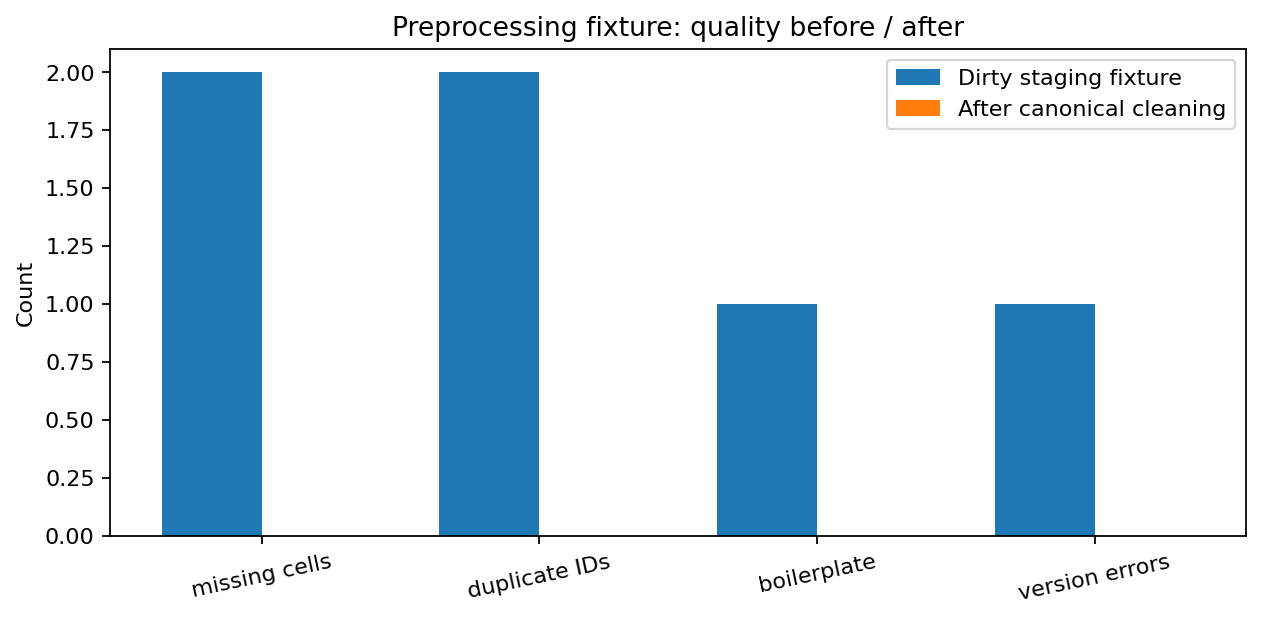

02_baseline_vs_hybrid.png


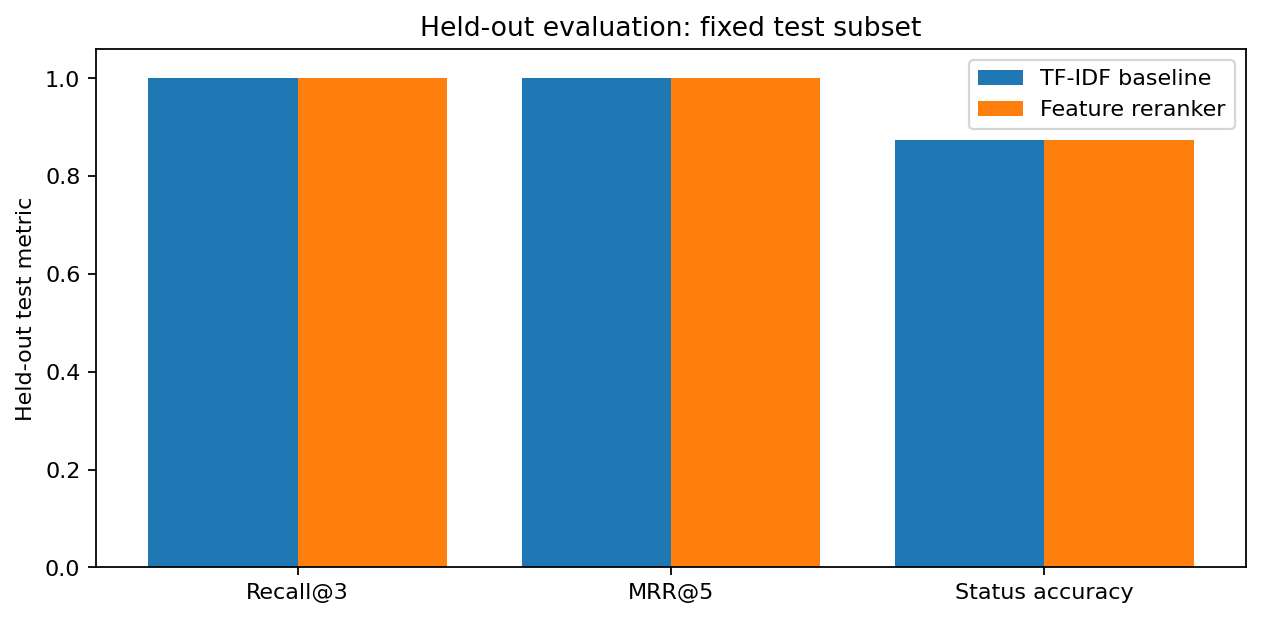

03_feature_importance.png


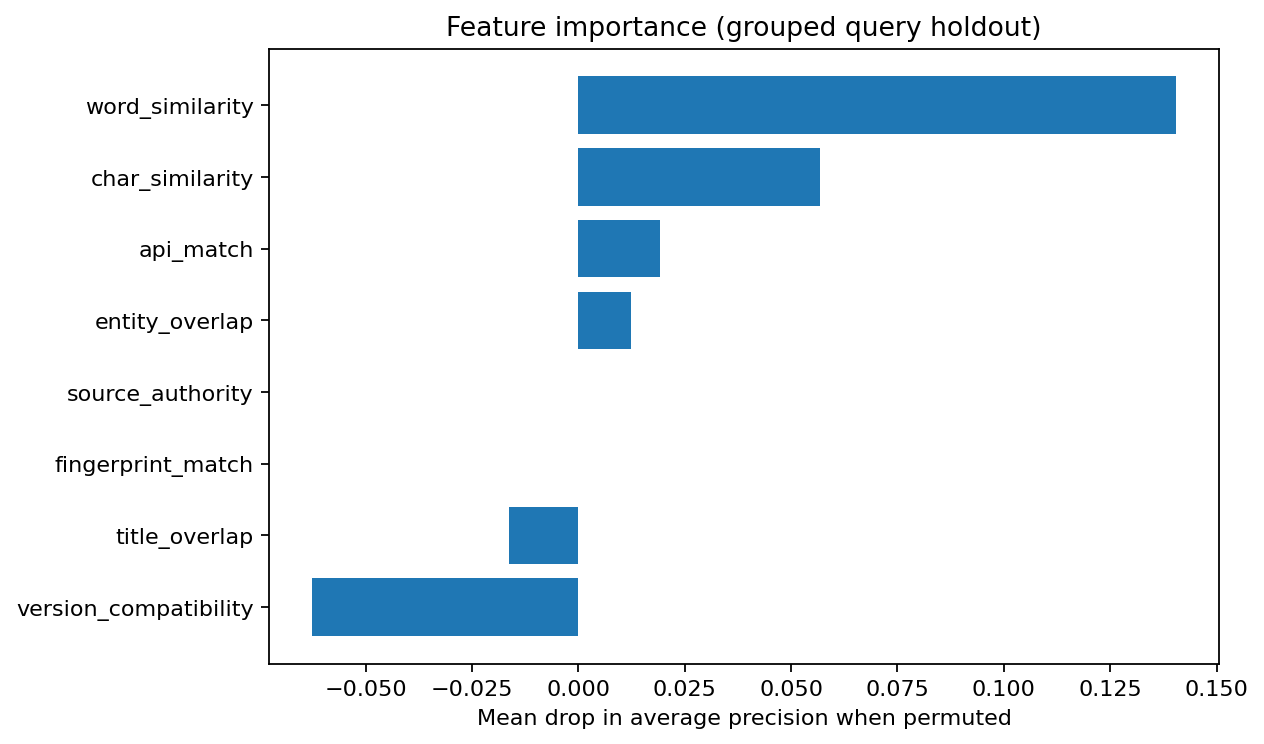

04_corpus_lengths.png


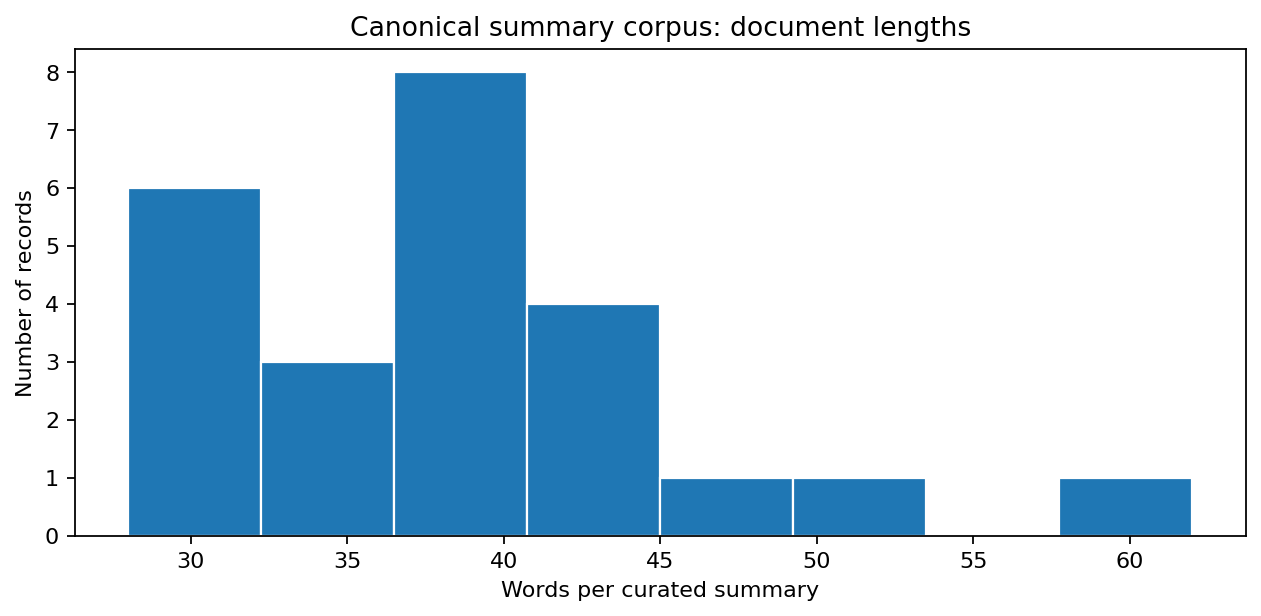

In [8]:
for name in ['01_quality_before_after.png','02_baseline_vs_hybrid.png','03_feature_importance.png','04_corpus_lengths.png']:
    print(name)
    display(Image(filename=str(Path('docs/figures')/name),width=730))


## 6 · Error analysis and risk review

- **Success:** citations carry direct manufacturer URLs; wrong-version-only instructions are hard-filtered; no runtime paid API or GPU; the fallback is always available.
- **Limitations:** curated small-domain corpus (24 records), no verified 80–150-page ingestion run, only 43 manually authored queries, no embedding/FAISS proof, and no measured clinical-like calibrated probabilities.
- **Safety:** unsafe battery modifications are escalated; hypothetical repairs never execute; physical procedures should be checked in the current manual and with a supervisor.
- **Next experiments:** run the online importer and verify code blocks; label 150–250 independent issue questions; run dedicated lexical vs MiniLM/FAISS ablation; calibrate abstention thresholds with a distinct validation set; evaluate citation correctness with blind human judges.


In [9]:
rows=pd.read_csv('results/per_question_results.csv')
errors=rows[(rows['recall3']==0)|(rows['status_correct']==0)|(rows['intent_correct']==0)]
display(errors[['id','split','question','top3','pred_status','intent_expected','intent_pred']].head(16))


,id,split,question,top3,pred_status,intent_expected,intent_pred
3,q004,development,Where is the zero button on V2?,"['zero_v2', 'gpio_hat', 'versions']",answered,calibration,hardware
14,q015,test,Which command starts the wake-up demonstration?,"['demo', 'safety', 'unstable']",answered,software,other
22,q023,development,My speaker has no audio output after boot,"['mic', 'sound', 'voice']",answered,audio,audio
26,q027,development,Can I swap the camera cable while the Raspberr...,"['camera', 'safety', 'install_error']",answered,camera,power
29,q030,test,IMU and light board both not working simultane...,"['imu', 'led', 'sensors']",answered,imu,rgb
30,q031,development,How much current does PiDog USB-C charger requ...,"['power', 'safety', 'unstable']",answered,power,other
35,q036,development,My PiDog is not moving,"['sensors', 'install', 'led']",escalate,motion,other
36,q037,development,It is broken,"['speaker', 'action_sequence', 'led']",clarify,other,other
37,q038,development,"Help, not working","['led', 'touch', 'gpio_hat']",clarify,other,other
39,q040,test,How do I cook pasta al dente?,"['touch', 'power', 'gpio_hat']",answered,other,other


## 7 · Collaboration and academic integrity

The midterm plan gave **José Tuozzo** pipeline integration and evaluation; **Kim Nguyen** data sourcing, preprocessing and quality; **Huu Huynh** retrieval, response generation, UI and testing. These are *assigned responsibilities*, not proof of implementation or of authorship of the original plan. The PDF and `docs/CONTRIBUTIONS_TEMPLATE.md` provide a verification form for each teammate to document completed tasks, diagram creation and references before final submission. Do not sign for someone else.

## References
1. [SunFounder PiDog documentation](https://docs.sunfounder.com/projects/pidog/en/latest/)
2. [SunFounder PiDog FAQ](https://docs.sunfounder.com/projects/pidog/en/latest/faq.html)
3. [SunFounder calibration instructions](https://docs.sunfounder.com/projects/pidog/en/latest/python/py_0_calibrate.html)
4. [SunFounder preset action reference](https://docs.sunfounder.com/projects/pidog/en/latest/python/py_b6_preset_action.html)
5. [SunFounder Robot HAT](https://docs.sunfounder.com/projects/robot-hat/en/latest/)
6. [SunFounder PiDog GitHub](https://github.com/sunfounder/pidog)

*End of notebook — output is reproducible with `python -m roboguide.evaluation` and `python -m pytest -q`.*
